# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Lulu Putri Aprilia
- **Email:** luluputriapriliaa@gmail.com
- **ID Dicoding:** DS535B6X0922

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1: Analisis Segmentasi Pelanggan (RFM)**
Bagaimana segmentasi pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) menggunakan seluruh periode transaksi yang tersedia pada dataset (September 2016 – Oktober 2018), dan segmen mana yang menyumbang revenue terbesar?
- **Pertanyaan 2: Ketepatan Pengiriman dan Kepuasan Pelanggan**
  Bagaimana perbandingan rata-rata skor ulasan pelanggan antara pesanan yang diterima tepat waktu dan pesanan yang mengalami keterlambatan pengiriman selama periode Januari 2017 – Oktober 2018, dan seberapa besar selisih kepuasan di antara keduanya?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import glob
import os
import datetime as dt

## Data Wrangling
Proses ini mencakup pengumpulan dataset yang dibutuhkan, pemeriksaan kualitas data untuk mengidentifikasi permasalahan, serta pembersihan data berdasarkan hasil pemeriksaan. Data yang telah dipersiapkan selanjutnya digunakan dalam proses Exploratory Data Analysis (EDA) untuk menjawab pertanyaan bisnis yang telah ditentukan.

### Gathering Data

#### Memuat dan Mengidentifikasi Dataset
**Tujuan:** Mengumpulkan dan memuat seluruh dataset E-Commerce Public Dataset dari Olist ke dalam DataFrame menggunakan library Pandas.

Pada tahap ini, seluruh file CSV yang tersedia dibaca dan disimpan dalam sebuah dictionary bernama `dataframes`. Setiap dataset diidentifikasi berdasarkan nama tabelnya, kemudian diperiksa jumlah baris dan kolomnya untuk mengetahui struktur awal data yang akan digunakan dalam analisis.

Pengumpulan data ini bertujuan memastikan seluruh tabel yang relevan tersedia dan dapat digunakan untuk mendukung proses analisis segmentasi pelanggan, transaksi, pembayaran, serta ulasan pelanggan.

In [2]:
# Mencari seluruh file CSV di folder utama
csv_files = glob.glob("*.csv")

# Menyiapkan tempat penyimpanan DataFrame
dataframes = {}

# Memuat seluruh dataset
for file in csv_files:
    nama_tabel = os.path.splitext(os.path.basename(file))[0]
    dataframes[nama_tabel] = pd.read_csv(file, low_memory=False)

# Menampilkan daftar dataset dan ukurannya
print("DAFTAR DATASET E-COMMERCE OLIST\n")

for nama, df in dataframes.items():
    print(f"{nama}: {df.shape[0]} baris, {df.shape[1]} kolom")

print("\nTotal tabel berhasil dimuat:", len(dataframes))


DAFTAR DATASET E-COMMERCE OLIST

geolocation_dataset: 1000163 baris, 5 kolom
customers_dataset: 99441 baris, 5 kolom
order_items_dataset: 112650 baris, 7 kolom
order_payments_dataset: 103886 baris, 5 kolom
product_category_name_translation: 71 baris, 2 kolom
products_dataset: 32951 baris, 9 kolom
sellers_dataset: 3095 baris, 4 kolom
orders_dataset: 99441 baris, 8 kolom
order_reviews_dataset: 99224 baris, 7 kolom

Total tabel berhasil dimuat: 9


**Insight:** (Opsional)
- Dataset E-Commerce Olist terdiri dari 9 tabel dengan struktur dan jumlah data yang berbeda. Tabel tersebut mencakup informasi pelanggan, pesanan, produk, penjual, pembayaran, ulasan, detail barang pesanan, lokasi geografis, serta terjemahan kategori produk.
- Dataset dengan jumlah baris terbesar adalah geolocation_dataset sebanyak 1.000.163 baris, sedangkan dataset product_category_name_translation memiliki jumlah baris paling sedikit, yaitu 71 baris. Perbedaan jumlah data tersebut menunjukkan bahwa setiap tabel memiliki tingkat detail informasi yang berbeda dan dapat dimanfaatkan untuk mendukung analisis bisnis melalui hubungan antartabel.

### Assessing Data

#### Mengidentifikasi Permasalahan Kualitas Data
**Tujuan:** Mengevaluasi kualitas setiap dataset untuk mengidentifikasi permasalahan yang dapat memengaruhi keakuratan hasil analisis.

Pemeriksaan dilakukan menggunakan beberapa metode, yaitu:

1. **Missing Values:** Mengidentifikasi jumlah dan persentase nilai kosong pada setiap dataset.
2. **Duplicate Data:** Memeriksa keberadaan baris duplikat yang berpotensi menyebabkan penghitungan data secara berulang.
3. **Data Types:** Memeriksa tipe data setiap kolom untuk memastikan kesesuaiannya dengan kebutuhan pengolahan dan analisis.

Hasil pemeriksaan digunakan untuk menentukan tindakan pembersihan yang sesuai. Permasalahan yang ditemukan akan ditangani pada tahap Cleaning Data dengan mempertimbangkan karakteristik dan fungsi masing-masing kolom.

In [3]:
# 1. Memeriksa Missing Values, Duplicate Data, dan Data Types
assessment_results = []

for nama, df in dataframes.items():

    # Menghitung missing values
    total_missing = df.isnull().sum().sum()

    # Menghitung persentase missing values
    missing_percentage = (
        total_missing / (df.shape[0] * df.shape[1])
    ) * 100

    # Menghitung duplicate rows
    total_duplicates = df.duplicated().sum()

    assessment_results.append({
        "Dataset": nama,
        "Jumlah Baris": df.shape[0],
        "Jumlah Kolom": df.shape[1],
        "Missing Values": total_missing,
        "Missing (%)": round(missing_percentage, 2),
        "Duplicate Rows": total_duplicates
    })

# Menampilkan ringkasan pemeriksaan
assessment_df = pd.DataFrame(assessment_results)

print("RINGKASAN ASSESSING DATA")
display(assessment_df)


# 2. Mengidentifikasi kolom yang memiliki Missing Values
print("\nIDENTIFIKASI MISSING VALUES")

for nama, df in dataframes.items():

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print(f"\nDataset: {nama}")
        print(missing)
    else:
        print(f"\nDataset: {nama} - Tidak ada missing values")

# 3. Memeriksa tipe data setiap dataset
print("\nPEMERIKSAAN DATA TYPES")

for nama, df in dataframes.items():
    print(f"\nDataset: {nama}")
    print(df.dtypes)


# 4. Menampilkan jumlah data duplikat
print("\nIDENTIFIKASI DUPLICATE DATA")

for nama, df in dataframes.items():
    jumlah_duplikat = df.duplicated().sum()
    print(f"{nama}: {jumlah_duplikat} baris duplikat")

# 5. Memeriksa Invalid Values
print("\nIDENTIFIKASI INVALID VALUES")

# Memeriksa review_score di luar rentang 1-5
review_df = dataframes['order_reviews_dataset']

invalid_review = review_df[
    ~review_df['review_score'].between(1, 5)
]

print("Invalid review_score:", len(invalid_review))

# Memeriksa nilai pembayaran negatif
payment_df = dataframes['order_payments_dataset']

invalid_payment = payment_df[
    payment_df['payment_value'] < 0
]

print("Invalid payment_value:", len(invalid_payment))

RINGKASAN ASSESSING DATA


,Dataset,Jumlah Baris,Jumlah Kolom,Missing Values,Missing (%),Duplicate Rows
0,geolocation_dataset,1000163,5,0,0.00,261831
1,customers_dataset,99441,5,0,0.00,0
2,order_items_dataset,112650,7,0,0.00,0
3,order_payments_dataset,103886,5,0,0.00,0
4,product_category_name_translation,71,2,0,0.00,0
5,products_dataset,32951,9,2448,0.83,0
6,sellers_dataset,3095,4,0,0.00,0
7,orders_dataset,99441,8,4908,0.62,0
8,order_reviews_dataset,99224,7,145903,21.01,0



IDENTIFIKASI MISSING VALUES

Dataset: geolocation_dataset - Tidak ada missing values

Dataset: customers_dataset - Tidak ada missing values

Dataset: order_items_dataset - Tidak ada missing values

Dataset: order_payments_dataset - Tidak ada missing values

Dataset: product_category_name_translation - Tidak ada missing values

Dataset: products_dataset
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Dataset: sellers_dataset - Tidak ada missing values

Dataset: orders_dataset
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Dataset: order_reviews_dataset
review_comment_title      87656
review_comment_message    58247
dtype: int64

PEMERIKSAAN DATA TYPES

Dataset: geolocation

**Steps to Take:**
- Menangani missing values pada products_dataset, orders_dataset, dan order_reviews_dataset dengan mempertimbangkan fungsi masing-masing kolom. Data yang bersifat deskriptif dapat diisi dengan nilai pengganti yang sesuai, sedangkan data penting untuk analisis perlu diperiksa sebelum dihapus.
- Menghapus baris duplikat pada geolocation_dataset menggunakan metode drop_duplicates() agar tidak terjadi penghitungan data geografis secara berulang.
- Mempertahankan nilai review_score dan payment_value karena hasil pemeriksaan tidak menemukan nilai yang melanggar aturan validitas pada kedua kolom tersebut.

**Insight:** (Opsional)

Berdasarkan hasil pemeriksaan kualitas data, ditemukan beberapa permasalahan pada dataset E-Commerce Public Dataset.

Permasalahan pertama adalah missing values yang ditemukan pada beberapa dataset, terutama order_reviews_dataset sebanyak 145.903 nilai kosong (21,01%), products_dataset sebanyak 2.448 nilai kosong (8,83%), dan orders_dataset sebanyak 4.908 nilai kosong (0,82%).

Permasalahan kedua adalah duplicate data yang ditemukan pada geolocation_dataset sebanyak 281.831 baris duplikat. Duplikasi ini perlu diperhatikan karena berpotensi menyebabkan pengulangan informasi apabila data digunakan dalam proses pengolahan lebih lanjut.

Selain itu, pemeriksaan data types dilakukan untuk memastikan tipe data setiap kolom sesuai dengan kebutuhan analisis. Pemeriksaan invalid values juga dilakukan untuk mengevaluasi kesesuaian nilai dengan aturan dan karakteristik masing-masing kolom.

Temuan dari tahap Assessing Data selanjutnya digunakan sebagai dasar dalam menentukan tindakan pembersihan pada tahap Cleaning Data. Penanganan dilakukan dengan mempertimbangkan karakteristik setiap dataset agar informasi penting tetap dapat dipertahankan.

### Cleaning Data

#### Menangani Permasalahan Kualitas Data
**Tujuan:** Memperbaiki permasalahan kualitas data yang telah ditemukan pada tahap Assessing Data agar dataset siap digunakan dalam proses analisis.

Pembersihan dilakukan berdasarkan karakteristik setiap tabel, meliputi penanganan missing values, penghapusan data duplikat, serta penyesuaian tipe data yang diperlukan.

Setiap tindakan pembersihan dilakukan dengan mempertimbangkan fungsi informasi di dalam dataset agar tidak menghilangkan data penting yang masih dibutuhkan untuk menjawab pertanyaan bisnis. Setelah proses pembersihan selesai, dilakukan pemeriksaan kembali untuk memastikan kualitas data telah meningkat dan data siap digunakan pada tahap EDA.

In [4]:
# CLEANING DATA

# 1. Membersihkan products_dataset
products = dataframes['products_dataset'].copy()

# Mengisi missing values pada kolom kategori
products['product_category_name'] = products['product_category_name'].fillna('unknown')

# Mengisi missing values pada kolom numerik menggunakan median
product_numeric_cols = [
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

for col in product_numeric_cols:
    if products[col].isnull().any():
        products[col] = products[col].fillna(products[col].median())

dataframes['products_dataset'] = products


# 2. Membersihkan orders_dataset
orders = dataframes['orders_dataset'].copy()

# Mengubah kolom tanggal menjadi datetime
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

# Missing values tanggal tetap dipertahankan karena memiliki makna operasional
dataframes['orders_dataset'] = orders


# 3. Membersihkan order_reviews_dataset
reviews = dataframes['order_reviews_dataset'].copy()

# Mengisi teks ulasan yang kosong tanpa mengubah skor penilaian
reviews['review_comment_title'] = reviews['review_comment_title'].fillna(
    'Tidak ada judul ulasan'
)

reviews['review_comment_message'] = reviews['review_comment_message'].fillna(
    'Tidak ada komentar ulasan'
)

# Mengubah kolom tanggal ulasan menjadi datetime
reviews['review_creation_date'] = pd.to_datetime(
    reviews['review_creation_date'], errors='coerce'
)

reviews['review_answer_timestamp'] = pd.to_datetime(
    reviews['review_answer_timestamp'], errors='coerce'
)

dataframes['order_reviews_dataset'] = reviews


# 4. Membersihkan geolocation_dataset
geolocation = dataframes['geolocation_dataset'].copy()

jumlah_duplikat_awal = geolocation.duplicated().sum()

geolocation = geolocation.drop_duplicates().reset_index(drop=True)

dataframes['geolocation_dataset'] = geolocation


# 5. Memeriksa hasil Cleaning Data
print("HASIL CLEANING DATA")
print("=" * 60)

for nama, df in dataframes.items():
    print(f"\nDataset: {nama}")
    print(f"Jumlah baris: {len(df)}")
    print(f"Missing values: {df.isnull().sum().sum()}")
    print(f"Duplicate rows: {df.duplicated().sum()}")

print("\nJumlah duplikat geolocation yang dihapus:",
      jumlah_duplikat_awal)
print("\nProses Cleaning Data selesai!")

# 6. Validasi khusus kolom setelah Cleaning Data
print("VALIDASI HASIL CLEANING")

# Validasi Products Dataset
print("\nProducts Dataset:")
print(dataframes['products_dataset'][product_numeric_cols].isnull().sum())
print("Missing kategori:",
      dataframes['products_dataset']['product_category_name'].isnull().sum())

# Validasi Order Reviews Dataset
print("\nOrder Reviews Dataset:")
print(dataframes['order_reviews_dataset'][
    ['review_comment_title', 'review_comment_message']
].isnull().sum())

# Validasi tipe data tanggal
print("\nTipe Data Tanggal Orders:")
print(dataframes['orders_dataset'][date_cols].dtypes)

# Validasi Geolocation
print("\nDuplicate Geolocation:")
print(dataframes['geolocation_dataset'].duplicated().sum())

HASIL CLEANING DATA

Dataset: geolocation_dataset
Jumlah baris: 738332
Missing values: 0
Duplicate rows: 0

Dataset: customers_dataset
Jumlah baris: 99441
Missing values: 0
Duplicate rows: 0

Dataset: order_items_dataset
Jumlah baris: 112650
Missing values: 0
Duplicate rows: 0

Dataset: order_payments_dataset
Jumlah baris: 103886
Missing values: 0
Duplicate rows: 0

Dataset: product_category_name_translation
Jumlah baris: 71
Missing values: 0
Duplicate rows: 0

Dataset: products_dataset
Jumlah baris: 32951
Missing values: 0
Duplicate rows: 0

Dataset: sellers_dataset
Jumlah baris: 3095
Missing values: 0
Duplicate rows: 0

Dataset: orders_dataset
Jumlah baris: 99441
Missing values: 4908
Duplicate rows: 0

Dataset: order_reviews_dataset
Jumlah baris: 99224
Missing values: 0
Duplicate rows: 0

Jumlah duplikat geolocation yang dihapus: 261831

Proses Cleaning Data selesai!
VALIDASI HASIL CLEANING

Products Dataset:
product_name_lenght           0
product_description_lenght    0
product_pho

**Insight:** (Opsional)

- Berdasarkan proses pembersihan data, sebagian besar permasalahan missing values berhasil ditangani sesuai dengan karakteristik masing-masing dataset. Pada products_dataset, nilai kosong pada kategori produk diisi menggunakan label 'unknown', sedangkan nilai kosong pada kolom numerik diisi menggunakan nilai median. Pada order_reviews_dataset, kolom judul dan komentar ulasan yang kosong diisi dengan keterangan yang sesuai tanpa mengubah skor penilaian pelanggan.

  Sementara itu, missing values pada orders_dataset tetap dipertahankan sebanyak 4.908 nilai karena sebagian berkaitan dengan informasi waktu persetujuan dan pengiriman pesanan yang memiliki makna operasional. Nilai kosong tersebut tidak langsung dihapus agar informasi mengenai status dan proses pesanan tetap terjaga.

  Selain itu, proses penghapusan duplikasi pada geolocation_dataset berhasil mengurangi sebanyak 261.831 baris duplikat, dari 1.000.163 menjadi 738.332 baris. Setelah proses cleaning, tidak ditemukan lagi baris duplikat pada dataset tersebut. Secara keseluruhan, proses cleaning telah menangani permasalahan kualitas data yang ditemukan dengan tetap mempertahankan informasi penting untuk tahap analisis selanjutnya.

## Exploratory Data Analysis (EDA)

### Tujuan Exploratory Data Analysis

Exploratory Data Analysis (EDA) merupakan tahap eksplorasi untuk memahami karakteristik, pola, dan informasi yang terdapat dalam dataset setelah melalui proses pembersihan data.

Pada tahap ini, analisis dilakukan menggunakan statistik deskriptif, pengelompokan data, penggabungan tabel, dan agregasi untuk memperoleh informasi yang relevan dengan pertanyaan bisnis.

Eksplorasi dilakukan melalui tiga tahapan:

1. **Eksplorasi Umum Dataset:** Memahami struktur dataset, statistik deskriptif, distribusi status pesanan, metode pembayaran, skor ulasan pelanggan, dan nilai transaksi.

2. **Eksplorasi Segmentasi Pelanggan:** Mengidentifikasi karakteristik pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM), kemudian menganalisis jumlah pelanggan serta kontribusi total nilai pembayaran pada setiap segmen.

3. **Eksplorasi Ketepatan Pengiriman dan Kepuasan Pelanggan:** Mengelompokkan pesanan berdasarkan ketepatan waktu pengiriman, kemudian membandingkan rata-rata skor ulasan pelanggan antara pesanan yang diterima tepat waktu dan pesanan yang terlambat.

Hasil eksplorasi ini digunakan sebagai dasar dalam proses visualisasi data, penarikan kesimpulan, dan penyusunan rekomendasi bisnis.

In [5]:
# EXPLORATORY DATA ANALYSIS (EDA)

print("=" * 60)
print("EXPLORATORY DATA ANALYSIS - E-COMMERCE OLIST")
print("=" * 60)

# 1. Ringkasan seluruh dataset
print("\n1. RINGKASAN DATASET")

for nama, df in dataframes.items():
    print(f"\nDataset: {nama}")
    print(f"Jumlah baris dan kolom: {df.shape}")
    print(f"Jumlah data kosong: {df.isnull().sum().sum()}")
    print(f"Jumlah data duplikat: {df.duplicated().sum()}")

# 2. Statistik deskriptif dataset utama
print("\n" + "=" * 60)
print("2. STATISTIK DESKRIPTIF")

for nama in ["orders_dataset", "order_items_dataset",
             "order_payments_dataset", "order_reviews_dataset",
             "products_dataset"]:
    if nama in dataframes:
        print(f"\nStatistik {nama}:")
        print(dataframes[nama].describe(include="all").to_string())

# 3. Analisis status pesanan
print("\n" + "=" * 60)
print("3. DISTRIBUSI STATUS PESANAN")

if "orders_dataset" in dataframes:
    print(dataframes["orders_dataset"]["order_status"]
          .value_counts().to_string())

# 4. Analisis metode pembayaran
print("\n" + "=" * 60)
print("4. DISTRIBUSI METODE PEMBAYARAN")

if "order_payments_dataset" in dataframes:
    print(dataframes["order_payments_dataset"]
          ["payment_type"].value_counts().to_string())

# 5. Distribusi skor ulasan pelanggan
print("\n" + "=" * 60)
print("5. DISTRIBUSI SKOR ULASAN PELANGGAN")

if "order_reviews_dataset" in dataframes:
    print(dataframes["order_reviews_dataset"]
          ["review_score"].value_counts().sort_index().to_string())

# 6. Analisis nilai transaksi
print("\n" + "=" * 60)
print("6. ANALISIS NILAI TRANSAKSI")

if "order_payments_dataset" in dataframes:
    print(dataframes["order_payments_dataset"]
          ["payment_value"].describe().to_string())

print("\nEDA tahap eksplorasi data berhasil diselesaikan!")

EXPLORATORY DATA ANALYSIS - E-COMMERCE OLIST

1. RINGKASAN DATASET

Dataset: geolocation_dataset
Jumlah baris dan kolom: (738332, 5)
Jumlah data kosong: 0
Jumlah data duplikat: 0

Dataset: customers_dataset
Jumlah baris dan kolom: (99441, 5)
Jumlah data kosong: 0
Jumlah data duplikat: 0

Dataset: order_items_dataset
Jumlah baris dan kolom: (112650, 7)
Jumlah data kosong: 0
Jumlah data duplikat: 0

Dataset: order_payments_dataset
Jumlah baris dan kolom: (103886, 5)
Jumlah data kosong: 0
Jumlah data duplikat: 0

Dataset: product_category_name_translation
Jumlah baris dan kolom: (71, 2)
Jumlah data kosong: 0
Jumlah data duplikat: 0

Dataset: products_dataset
Jumlah baris dan kolom: (32951, 9)
Jumlah data kosong: 0
Jumlah data duplikat: 0

Dataset: sellers_dataset
Jumlah baris dan kolom: (3095, 4)
Jumlah data kosong: 0
Jumlah data duplikat: 0

Dataset: orders_dataset
Jumlah baris dan kolom: (99441, 8)
Jumlah data kosong: 4908
Jumlah data duplikat: 0

Dataset: order_reviews_dataset
Jumlah b

**Insight:** (Opsional)
- Hasil Exploratory Data Analysis menunjukkan bahwa sebagian besar pesanan berhasil diselesaikan dengan status delivered sebanyak 96.478 pesanan. Metode pembayaran yang paling banyak digunakan adalah credit card sebanyak 76.795 transaksi, sedangkan mayoritas pelanggan memberikan rating 5 sebanyak 57.328 ulasan. Hal ini menunjukkan bahwa tingkat penyelesaian pesanan dan penilaian pelanggan cenderung positif.
- Dari sisi transaksi, nilai pembayaran rata-rata tercatat sebesar 154,10 dengan nilai maksimum 13.664,80. Sementara itu, analisis produk menunjukkan adanya variasi pada berat, ukuran, dan jumlah foto produk. Temuan ini dapat digunakan untuk memahami karakteristik transaksi, produk, serta perilaku pelanggan pada platform E-Commerce Olist.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana segmentasi pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) menggunakan seluruh periode transaksi yang tersedia pada dataset (September 2016 – Oktober 2018), dan segmen mana yang menyumbang revenue terbesar?

Periode transaksi:
Awal: 2016-09-04 21:15:19
Akhir: 2018-10-17 17:30:18


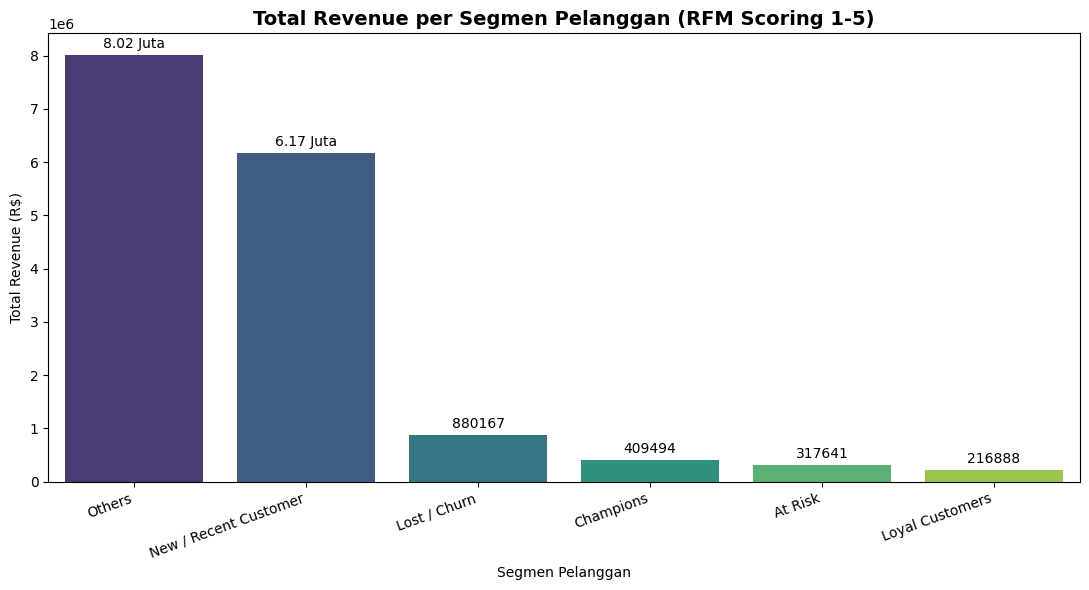

,Segment,Total_Revenue,Jumlah_Pelanggan,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue (%)
0,Others,8018819.79,40009,365.533005,1.000000,200.425399,50.09
1,New / Recent Customer,6165862.70,37309,140.889249,1.000000,165.264754,38.52
2,Lost / Churn,880166.92,15780,447.257414,1.000000,55.777371,5.50
3,Champions,409494.20,1072,137.406716,2.190299,381.990858,2.56
4,At Risk,317640.56,1054,433.403226,2.080645,301.366755,1.98
5,Loyal Customers,216887.95,871,232.727899,2.067738,249.010276,1.35


In [6]:
# --- PERTANYAAN 1: RFM ANALYSIS (RFM SCORING) ---

# 1. Siapkan data
rfm_df = dataframes['orders_dataset'].merge(
    dataframes['order_payments_dataset']
        .groupby('order_id')['payment_value'].sum().reset_index(),
    on='order_id',
    how='left'
)
rfm_df = rfm_df.merge(
    dataframes['customers_dataset'], on='customer_id', how='left'
)

# Konversi tanggal & buang transaksi tanpa nilai pembayaran
rfm_df['order_purchase_timestamp'] = pd.to_datetime(
    rfm_df['order_purchase_timestamp'], errors='coerce'
)
rfm_df = rfm_df.dropna(subset=['payment_value', 'order_purchase_timestamp'])

print("Periode transaksi:")
print("Awal:", rfm_df['order_purchase_timestamp'].min())
print("Akhir:", rfm_df['order_purchase_timestamp'].max())

# 2. Hitung RFM mentah (per pelanggan unik)
snapshot_date = rfm_df['order_purchase_timestamp'].max() + dt.timedelta(days=1)

rfm_agg = rfm_df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (snapshot_date - x.max()).days,  # Recency
    'order_id': 'nunique',                                                 # Frequency
    'payment_value': 'sum'                                                 # Monetary
}).reset_index()

rfm_agg.columns = ['customer_unique_id', 'Recency', 'Frequency', 'Monetary']

# 3. RFM Scoring
# --- Recency: pakai qcut (distribusi kontinu, aman) ---
rfm_agg['R_Score'] = pd.qcut(
    rfm_agg['Recency'], q=5, labels=[5, 4, 3, 2, 1]
).astype(int)

# --- Frequency: mayoritas pelanggan F=1 (one-time buyer).
# Menggunakan qcut pada rank(method='first') membuat skor F menjadi
# ARBITRER karena banyak nilai kembar (ties) dipecah acak.
# Solusi: binning manual yang bermakna secara bisnis.
def freq_score(f):
    if f >= 3:
        return 5
    elif f == 2:
        return 4
    else:
        return 1  # F == 1

rfm_agg['F_Score'] = rfm_agg['Frequency'].apply(freq_score)

# --- Monetary: qcut pada rank masih relatif aman untuk M (nilai kontinu),
rfm_agg['M_Score'] = pd.qcut(
    rfm_agg['Monetary'].rank(method='first'),
    q=5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm_agg['RFM_Score'] = (
    rfm_agg['R_Score'].astype(str)
    + rfm_agg['F_Score'].astype(str)
    + rfm_agg['M_Score'].astype(str)
)

# 4. Segmentasi berbasis skor RFM (rule-based, interpretable)
def rfm_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 4:
        return 'Loyal Customers'
    elif r >= 4 and f == 1:
        return 'New / Recent Customer'
    elif r <= 2 and f >= 4:
        return 'At Risk'
    elif r <= 2 and f == 1 and m <= 2:
        return 'Lost / Churn'
    else:
        return 'Others'

rfm_agg['Segment'] = rfm_agg.apply(rfm_segment, axis=1)

# 5. Hitung Revenue per Segmen
segment_revenue = rfm_agg.groupby('Segment').agg(
    Total_Revenue=('Monetary', 'sum'),
    Jumlah_Pelanggan=('customer_unique_id', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
).reset_index()

segment_revenue['Revenue (%)'] = (
    segment_revenue['Total_Revenue']
    / segment_revenue['Total_Revenue'].sum() * 100
).round(2)

segment_revenue = segment_revenue.sort_values(
    by='Total_Revenue', ascending=False
).reset_index(drop=True)

# 6. Visualisasi
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=segment_revenue,
    x='Segment',
    y='Total_Revenue',
    hue='Segment',
    palette='viridis',
    legend=False
)
plt.title(
    'Total Revenue per Segmen Pelanggan (RFM Scoring 1-5)',
    fontsize=14, fontweight='bold'
)
plt.xlabel('Segmen Pelanggan')
plt.ylabel('Total Revenue (R$)')
plt.xticks(rotation=20, ha='right')

for container in ax.containers:
    labels = [
        f'{v.get_height()/1e6:.2f} Juta'
        if v.get_height() > 1e6 else f'{v.get_height():.0f}'
        for v in container
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.tight_layout()
plt.show()

display(segment_revenue)

### Pertanyaan 2: Bagaimana perbandingan rata-rata skor ulasan pelanggan antara pesanan yang diterima tepat waktu dan pesanan yang mengalami keterlambatan pengiriman selama periode Januari 2017 – Oktober 2018, dan seberapa besar selisih kepuasan di antara keduanya?

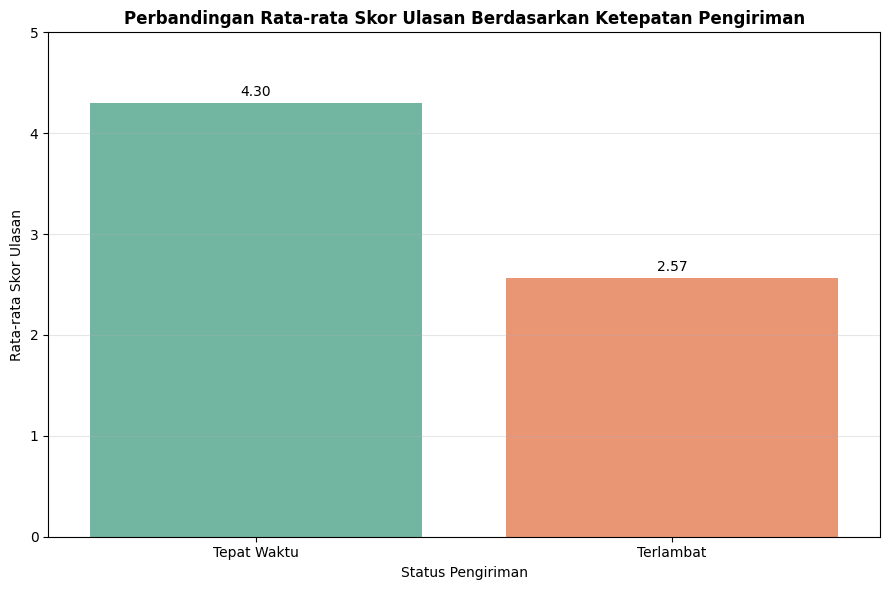

,delivery_status,average_review_score,total_orders
0,Tepat Waktu,4.295086,87902
1,Terlambat,2.566728,7658


Total pesanan yang dianalisis: 95560
Selisih rata-rata skor ulasan: 1.73


In [7]:
# --- PERTANYAAN 2: PERBANDINGAN SKOR ULASAN ---

# Mengambil dataset pesanan dan ulasan
orders_review = dataframes['orders_dataset'].copy()
reviews_analysis = dataframes['order_reviews_dataset'].copy()

# Memastikan kolom tanggal bertipe datetime
date_columns = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_review[col] = pd.to_datetime(
        orders_review[col], errors='coerce'
    )

# Memastikan skor ulasan bertipe numerik
reviews_analysis['review_score'] = pd.to_numeric(
    reviews_analysis['review_score'], errors='coerce'
)

# Menghitung rata-rata skor ulasan per pesanan
review_per_order = (
    reviews_analysis.groupby('order_id')['review_score']
    .mean()
    .reset_index()
)

# Menggabungkan pesanan dengan ulasan
delivery_review = orders_review.merge(
    review_per_order,
    on='order_id',
    how='inner'
)

# Membatasi periode pembelian Januari 2017 - Oktober 2018
delivery_review = delivery_review[
    (delivery_review['order_purchase_timestamp'] >= '2017-01-01') &
    (delivery_review['order_purchase_timestamp'] < '2018-11-01')
].copy()

# Filter pesanan delivered dengan tanggal lengkap
delivery_review = delivery_review[
    (delivery_review['order_status'] == 'delivered') &
    (delivery_review['order_delivered_customer_date'].notna()) &
    (delivery_review['order_estimated_delivery_date'].notna()) &
    (delivery_review['review_score'].notna())
].copy()

# Menghitung keterlambatan pengiriman
delivery_review['delivery_delay_days'] = (
    delivery_review['order_delivered_customer_date'] -
    delivery_review['order_estimated_delivery_date']
).dt.total_seconds() / 86400

# Mengelompokkan status pengiriman
delivery_review['delivery_status'] = delivery_review[
    'delivery_delay_days'
].apply(
    lambda x: 'Terlambat' if x > 0 else 'Tepat Waktu'
)

# Menghitung rata-rata skor ulasan dan jumlah pesanan
review_comparison = delivery_review.groupby(
    'delivery_status'
).agg(
    average_review_score=('review_score', 'mean'),
    total_orders=('order_id', 'nunique')
).reindex(['Tepat Waktu', 'Terlambat']).reset_index()

# Membuat visualisasi
plt.figure(figsize=(9, 6))
ax = sns.barplot(
    data=review_comparison,
    x='delivery_status',
    y='average_review_score',
    hue='delivery_status',
    palette='Set2',
    legend=False
)

plt.title(
    'Perbandingan Rata-rata Skor Ulasan Berdasarkan Ketepatan Pengiriman',
    fontsize=12,
    fontweight='bold'
)
plt.xlabel('Status Pengiriman')
plt.ylabel('Rata-rata Skor Ulasan')
plt.ylim(0, 5)
plt.grid(axis='y', alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

display(review_comparison)
print("Total pesanan yang dianalisis:", delivery_review['order_id'].nunique())

# Menghitung selisih rata-rata skor ulasan
score_tepat_waktu = review_comparison.loc[
    review_comparison['delivery_status'] == 'Tepat Waktu',
    'average_review_score'
].iloc[0]

score_terlambat = review_comparison.loc[
    review_comparison['delivery_status'] == 'Terlambat',
    'average_review_score'
].iloc[0]

selisih_skor = score_tepat_waktu - score_terlambat

print(f"Selisih rata-rata skor ulasan: {selisih_skor:.2f}")

**Insight:** (Opsional)

**Insight Pertanyaan 1**
Berdasarkan hasil analisis RFM, segmen Others memberikan kontribusi revenue terbesar sebesar 50,09%, diikuti oleh New / Recent Customer sebesar 38,52%. Sementara itu, segmen Lost / Churn menyumbang 5,50%, Champions sebesar 2,56%, At Risk sebesar 1,98%, dan Loyal Customers sebesar 1,35%.
Hasil tersebut menunjukkan bahwa kontribusi revenue terbesar berasal dari pelanggan yang belum termasuk dalam kategori segmentasi khusus. Selain itu, tingginya kontribusi New / Recent Customer menunjukkan bahwa pelanggan dengan frekuensi pembelian rendah juga memberikan kontribusi transaksi yang cukup besar.
Oleh karena itu, perusahaan perlu memperhatikan strategi retensi pelanggan, khususnya mendorong pelanggan baru agar melakukan pembelian berulang dan meningkatkan loyalitas pelanggan.

**Rekomendasi Action Item (Berdasarkan RFM):**
   1. Others (50,09% revenue, 40.009 pelanggan): Segmen terbesar. Perlu profiling lebih lanjut untuk memahami karakteristiknya (kemungkinan R sedang/rendah, F=1, M menengah). Lakukan kampanye cross-sell / bundle untuk mendorong transaksi kedua.
   2. New / Recent Customer (38,52% revenue, 37.309 pelanggan): Pelanggan baru dengan Recency baik (rata-rata 141 hari). Kirim email follow-up berisi diskon pembelian kedua agar naik ke segmen Loyal.
   3. Lost / Churn (5,50% revenue, 15.780 pelanggan): Recency sangat tinggi (447 hari). Evaluasi kelayakan re-engagement; jika biaya terlalu tinggi, fokuskan sumber daya ke segmen lain.
   4. Champions (2,56% revenue, 1.072 pelanggan): Meski kontribusi revenue kecil, Avg_Monetary (≈R$ 382) dan Avg_Frequency (2,19) tertinggi. Pertahankan dengan layanan premium, early access produk baru, dan program referral.
   5. At Risk (1,98% revenue, 1.054 pelanggan): Recency tinggi (433 hari) tapi F dan M masih tinggi. Lakukan retargeting dengan penawaran menarik sebelum benar-benar churn.
   6. Loyal Customers (1,35% revenue, 871 pelanggan): Berikan program loyalitas (poin, diskon khusus, akses awal flash sale) untuk mendorong pembelian ulang dan mencegah penurunan ke Churn.


**Insight Pertanyaan 2**
Berdasarkan hasil analisis, pesanan yang diterima tepat waktu memiliki rata-rata skor ulasan sebesar 4,30 dari skala 5, dengan total 87.902 pesanan. Sementara itu, pesanan yang mengalami keterlambatan pengiriman memiliki rata-rata skor ulasan sebesar 2,57 dari skala 5, dengan total 7.658 pesanan.

Terdapat selisih rata-rata skor ulasan sebesar 1,73 poin antara kedua kelompok tersebut. Hasil ini menunjukkan bahwa pesanan yang diterima tepat waktu cenderung memperoleh penilaian lebih tinggi dibandingkan pesanan yang mengalami keterlambatan.

Dengan demikian, ketepatan waktu pengiriman memiliki hubungan dengan tingkat kepuasan pelanggan. Perusahaan perlu meningkatkan pengelolaan proses pengiriman agar pesanan dapat diterima sesuai estimasi waktu yang telah ditentukan.

## Analisis Lanjutan (Opsional)

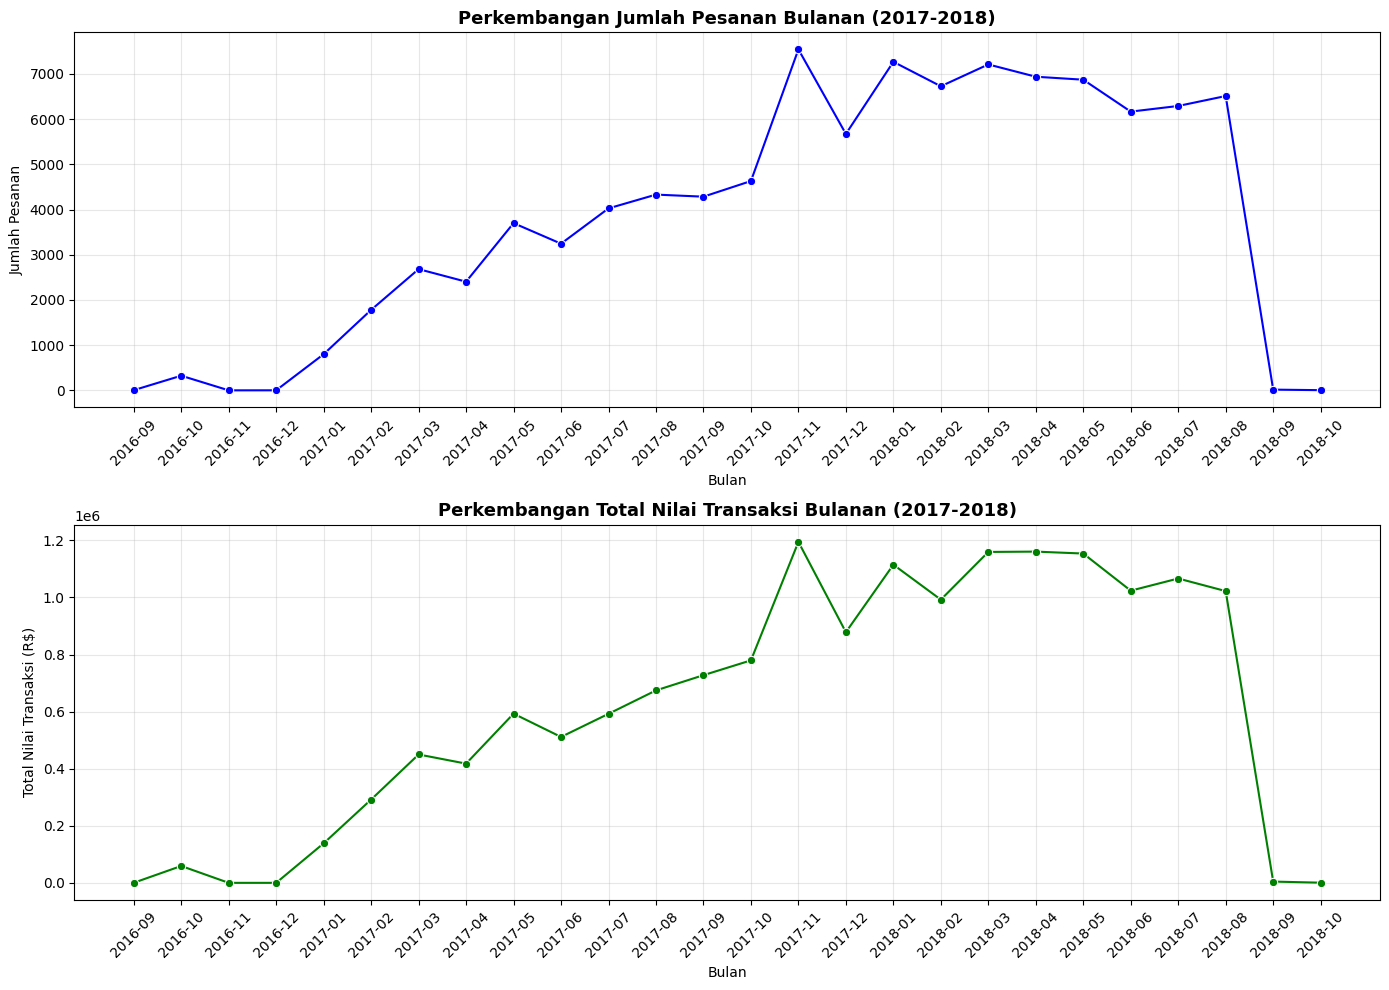

,month,total_orders,total_revenue
0,2016-09,4,252.24
1,2016-10,324,59090.48
2,2016-11,0,0.00
3,2016-12,1,19.62
4,2017-01,800,138488.04
5,2017-02,1780,291908.01
6,2017-03,2682,449863.60
7,2017-04,2404,417788.03
8,2017-05,3700,592918.82
9,2017-06,3245,511276.38


In [8]:
# --- ANALISIS LANJUTAN: TREN PENJUALAN BULANAN ---

# Mengambil dataset
orders_analysis = dataframes['orders_dataset'].copy()
payments_analysis = dataframes['order_payments_dataset'].copy()

# Memastikan tipe data datetime
orders_analysis['order_purchase_timestamp'] = pd.to_datetime(
    orders_analysis['order_purchase_timestamp'],
    errors='coerce'
)

# Total pembayaran per pesanan
payment_per_order = (
    payments_analysis.groupby('order_id')['payment_value']
    .sum()
    .reset_index()
)

# Gabungkan data
sales_data = orders_analysis.merge(
    payment_per_order,
    on='order_id',
    how='left'
)

# Filter periode transaksi
sales_data = sales_data[
    (sales_data['order_purchase_timestamp'] >= '2016-09-01') &
    (sales_data['order_purchase_timestamp'] < '2018-11-01')
].copy()

# Kolom bulan
sales_data['month'] = (
    sales_data['order_purchase_timestamp'].dt.to_period('M')
)

# Agregasi bulanan
monthly_sales = sales_data.groupby('month').agg(
    total_orders=('order_id', 'nunique'),
    total_revenue=('payment_value', 'sum')
).reset_index()

# Lengkapi seluruh bulan dalam periode analisis
all_months = pd.period_range(
    start='2016-09',
    end='2018-10',
    freq='M'
)

monthly_sales = (
    monthly_sales.set_index('month')
    .reindex(all_months, fill_value=0)
    .rename_axis('month')
    .reset_index()
)

monthly_sales['month'] = monthly_sales['month'].astype(str)

# Visualisasi
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# 1. Grafik Jumlah Pesanan
sns.lineplot(
    data=monthly_sales,
    x='month',
    y='total_orders',
    marker='o',
    color='blue',
    ax=axes[0]
)
axes[0].set_title('Perkembangan Jumlah Pesanan Bulanan (2017-2018)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Bulan')
axes[0].set_ylabel('Jumlah Pesanan')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)

# 2. Grafik Total Nilai Transaksi
sns.lineplot(
    data=monthly_sales,
    x='month',
    y='total_revenue',
    marker='o',
    color='green',
    ax=axes[1]
)
axes[1].set_title('Perkembangan Total Nilai Transaksi Bulanan (2017-2018)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Bulan')
axes[1].set_ylabel('Total Nilai Transaksi (R$)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(monthly_sales)

**Insight:** (Opsional) Tren Penjualan

**Insight: Tren Penjualan**

1. Jumlah pesanan dan total nilai transaksi menunjukkan tren peningkatan yang cukup signifikan sepanjang tahun 2017. Hal ini menggambarkan adanya pertumbuhan aktivitas penjualan dibandingkan periode awal pengamatan pada tahun 2016.

2. Jumlah pesanan mencapai puncaknya pada November 2017 dengan sekitar 7.500 pesanan. Pada bulan yang sama, total nilai transaksi juga mencapai titik tertinggi, yaitu sekitar R$1,19 juta. Hal ini menunjukkan bahwa November 2017 merupakan periode dengan aktivitas penjualan tertinggi selama pengamatan.

3. Memasuki tahun 2018, jumlah pesanan dan total nilai transaksi relatif tinggi, meskipun mengalami beberapa fluktuasi. Setelah mencapai tingkat yang tinggi pada awal hingga pertengahan tahun, aktivitas penjualan mulai menunjukkan penurunan menjelang Agustus 2018.

4. Pergerakan jumlah pesanan dan total nilai transaksi menunjukkan pola yang relatif searah. Namun, peningkatan jumlah pesanan tidak selalu menghasilkan peningkatan nilai transaksi dalam proporsi yang sama karena setiap pesanan memiliki nilai pembayaran yang berbeda.

5. Data September dan Oktober 2018 menunjukkan nilai nol pada kedua grafik. Kondisi ini perlu diperhatikan karena dapat mengindikasikan data yang belum lengkap, bukan berarti tidak terdapat aktivitas penjualan. Oleh karena itu, kedua bulan tersebut tidak digunakan sebagai dasar untuk menyimpulkan penurunan penjualan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis RFM, segmen Others dan New / Recent Customer mendominasi kontribusi revenue dengan persentase masing-masing sebesar 50,09% dan 38,52%. Hal ini menunjukkan bahwa sebagian besar nilai transaksi berasal dari pelanggan yang belum termasuk dalam kategori segmentasi khusus serta pelanggan dengan frekuensi pembelian rendah.
Meskipun segmen Champions hanya menyumbang 2,56% dari total revenue, segmen ini memiliki rata-rata nilai transaksi (Monetary) dan frekuensi pembelian (Frequency) tertinggi. Sementara itu, segmen At Risk (1,98%) dan Loyal Customers (1,35%) memiliki kontribusi revenue yang relatif kecil sehingga tetap perlu diperhatikan melalui strategi retensi pelanggan.
Dengan demikian, perusahaan perlu memprioritaskan upaya mempertahankan pelanggan bernilai tinggi, mendorong pembelian berulang dari pelanggan baru, serta melakukan pendekatan khusus terhadap pelanggan yang berisiko berhenti melakukan transaksi.

- **Conclusion pertanyaan 2:** Berdasarkan hasil analisis, terdapat perbedaan rata-rata skor ulasan antara pesanan yang diterima tepat waktu dan pesanan yang mengalami keterlambatan pengiriman.

  Pesanan yang diterima tepat waktu memiliki rata-rata skor ulasan sebesar 4,30 dari skala 5, dengan total 87.902 pesanan. Sementara itu, pesanan yang mengalami keterlambatan memiliki rata-rata skor ulasan sebesar 2,57 dari skala 5, dengan total 7.658 pesanan.
  
  Terdapat selisih rata-rata skor ulasan sebesar 1,73 poin antara kedua kelompok tersebut. Hasil ini menunjukkan bahwa pesanan yang diterima tepat waktu cenderung memperoleh penilaian lebih tinggi dibandingkan pesanan yang mengalami keterlambatan.
  
  Dengan demikian, ketepatan waktu pengiriman memiliki keterkaitan dengan tingkat kepuasan pelanggan. Perusahaan perlu meningkatkan pengelolaan proses pengiriman dan pemantauan estimasi waktu kedatangan agar pesanan dapat diterima sesuai jadwal yang telah ditentukan.

  
- **Conclusion Analisis Lanjutan:**
  Berdasarkan hasil analisis, terdapat perbedaan rata-rata skor ulasan antara pesanan yang diterima tepat waktu dan pesanan yang mengalami keterlambatan pengiriman.
  
  Pesanan yang diterima tepat waktu memiliki rata-rata skor ulasan sebesar 4,30 dari skala 5, dengan total 87.902 pesanan. Sementara itu, pesanan yang mengalami keterlambatan memiliki rata-rata skor ulasan sebesar 2,57 dari skala 5, dengan total 7.658 pesanan.
  
  Terdapat selisih rata-rata skor ulasan sebesar 1,73 poin antara kedua kelompok tersebut. Hasil ini menunjukkan bahwa pesanan yang diterima tepat waktu cenderung memperoleh penilaian lebih tinggi dibandingkan pesanan yang mengalami keterlambatan.
  
  Dengan demikian, ketepatan waktu pengiriman memiliki keterkaitan dengan tingkat kepuasan pelanggan. Perusahaan perlu meningkatkan pengelolaan proses pengiriman dan pemantauan estimasi waktu kedatangan agar pesanan dapat diterima sesuai jadwal yang telah ditentukan.


**Rekomendasi Action Item:**

Berdasarkan hasil analisis yang telah dilakukan, berikut beberapa rekomendasi tindakan yang dapat diterapkan oleh perusahaan:

**1. Program Retensi dan Segmentasi Pelanggan (Berdasarkan RFM)**

* Untuk segmen Others, lakukan analisis lebih lanjut terhadap karakteristik pelanggan dan berikan promosi yang sesuai, seperti penawaran bundling atau cross-selling, untuk mendorong pembelian berulang.
* Untuk segmen Loyal Customers dan Champions, berikan program loyalitas berupa poin, diskon khusus, atau akses awal flash sale untuk mempertahankan pelanggan bernilai tinggi.
* Untuk segmen New / Recent Customer, lakukan cross-selling atau kirimkan email follow-up berisi diskon pembelian kedua agar pelanggan terdorong melakukan transaksi kembali.
* Untuk segmen At Risk dan Lost / Churn, lakukan kampanye retargeting melalui iklan atau email dengan penawaran menarik untuk mendorong pelanggan kembali bertransaksi.

**2. Meningkatkan Ketepatan Waktu Pengiriman** Melakukan evaluasi terhadap proses pengiriman, memilih mitra logistik yang memiliki kinerja baik, serta memantau status pengiriman secara berkala agar pesanan dapat diterima sesuai estimasi waktu.

**3. Mengurangi Keterlambatan Pesanan** Mengidentifikasi penyebab keterlambatan, baik dari sisi penjual, proses pengemasan, maupun pihak ekspedisi. Hasil evaluasi tersebut dapat digunakan untuk menentukan langkah perbaikan yang tepat dan mengurangi risiko keterlambatan pengiriman.

**4. Mengoptimalkan Strategi Penjualan Bulanan** Memanfaatkan informasi mengenai tren jumlah pesanan dan nilai transaksi bulanan untuk menyusun strategi promosi, mengelola stok produk, serta mempersiapkan kapasitas operasional pada periode dengan aktivitas transaksi tinggi, seperti November 2017 yang menjadi puncak penjualan dalam periode analisis.

**5. Melakukan Evaluasi Data Secara Berkala** Memantau perkembangan jumlah pesanan, nilai transaksi, ketepatan pengiriman, dan skor ulasan pelanggan secara berkala agar perusahaan dapat mengevaluasi efektivitas strategi bisnis serta mengambil keputusan berdasarkan data.
